# Colab 多目录科研工程：挂载、代码同步、Step/Epoch 断点续训与调试

先在 VS Code 右上角选择 **Select Kernel → Colab → New Colab Server → 可用 GPU → Python**，再依次执行下面的单元格。已有 GPU 服务器也可直接选择。

这个笔记本保存在本地；它启动的 Python 进程在 Colab 上运行，导入的多目录子包（`models/`、`datasets/`、`utils/`）也都在云端执行。不要用本地终端启动云端训练。

**核心能力：**
- **双端持久同步**：第 3 步自动将多文件代码增量同步至 Google Drive `project_workspace/`；Colab 掉线重连新实例时可自动从 Drive 拉取代码，免去重复上传。
- **Step/Batch 级安全中断**：点击停止按钮、达到 `--stop-after-step` 或触发 `checkpoint_every_steps` / `checkpoint_every_seconds` 时，在**当前 Batch 结束后立即保存完整检查点、中间状态（`intermediate_state.pt`）与最新权重（`last_model.pt`）并同步至 Drive**。
- **灵活调试续训**：支持在修改 `.py` 源码或调整学习率（`--lr`）、总轮数（`--epochs`）、`batch_size` 等超参后直接 `--resume auto` 继续训练。

## 1. 检查云端环境与 GPU

In [1]:
from pathlib import Path
import sys
import platform
import importlib.util
import subprocess

assert platform.system() == "Linux" and Path("/content").is_dir(), "请先选择 Colab 云端内核"
assert importlib.util.find_spec("torch"), "云端缺少 PyTorch，请检查运行时环境"
import torch
REQUIRE_GPU = True  # 仅想先用云端 CPU 演练时改为 False
print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA 可用:", torch.cuda.is_available())
if REQUIRE_GPU:
    assert torch.cuda.is_available(), "请选择 GPU 服务器；CPU 演练可将 REQUIRE_GPU 改为 False"
print("设备:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Python: /usr/bin/python3
PyTorch: 2.14.1+cu130
CUDA 可用: True
设备: NVIDIA A100-SXM4-40GB


## 2. 挂载 Drive 并验证写入（训练结果 + 项目代码工作区）

按弹窗完成 Google 授权。已挂载提示可正常继续，不需要强制重新挂载。

In [2]:
from google.colab import drive
import uuid
import os

drive.mount("/content/drive")
assert os.path.ismount("/content/drive"), "Drive 挂载未生效，请先恢复授权"
MY_DRIVE = Path("/content/drive/MyDrive")
assert MY_DRIVE.is_dir(), "Drive 没有挂载成功，请先恢复授权"
DRIVE_BASE = MY_DRIVE / "Colab_Training_Demo"
PERSISTENT_ROOT = DRIVE_BASE / "runs"
DRIVE_WORKSPACE = DRIVE_BASE / "project_workspace"
PERSISTENT_ROOT.mkdir(parents=True, exist_ok=True)
DRIVE_WORKSPACE.mkdir(parents=True, exist_ok=True)
probe = PERSISTENT_ROOT / (".write_test_" + uuid.uuid4().hex)
probe.write_text("drive-write-ok", encoding="utf-8")
assert probe.read_text(encoding="utf-8") == "drive-write-ok"
probe.unlink()
print("Drive 训练结果目录:", PERSISTENT_ROOT)
print("Drive 代码工作区目录:", DRIVE_WORKSPACE)

Mounted at /content/drive
Drive 训练结果目录: /content/drive/MyDrive/Colab_Training_Demo/runs
Drive 代码工作区目录: /content/drive/MyDrive/Colab_Training_Demo/project_workspace


In [ ]:
from pathlib import Path                                                                                                         
import subprocess                                                                                                                
                                                                                                                                     
REPO_URL = "https://github.com/uaago/-1.git"                                                                                     
REPO_DIR = Path("/content/github_repo")                                                                                          
                                                                                                                                     
if (REPO_DIR / ".git").is_dir():                                                                                                 
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)                                                
else:                                                                                                                            
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)         

## 3. 定位项目并同步至 Drive（新实例自动从 Drive 拉取代码）

首次运行：在本地 Explorer 对项目文件夹右键 → **Upload to Colab**，选择当前服务器后运行本单元格，会自动同步所有子目录代码到 `DRIVE_WORKSPACE`。
断线重连新运行时：如果 `/content` 下尚未重新上传代码，本单元格会自动从 `DRIVE_WORKSPACE` 恢复整个多目录工程到 `/content/colab_training_project`，可直接跳过重传继续训练。

In [ ]:
# 如有多个副本，手动改为 Path("/content/实际项目目录")；设为 None 则自动探测或从 Drive 恢复
#PROJECT = None
PROJECT=Path("/content/github_repo")
AUTO_SYNC_CODE_TO_DRIVE = True

def _load_code_sync_module(base_dir: Path):
    mod_path = base_dir / "colab_training_demo" / "utils" / "code_sync.py"
    spec = importlib.util.spec_from_file_location("_colab_code_sync", mod_path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

if PROJECT is None:
    roots = [Path("/content")] + [p for p in Path("/content").iterdir() if p.is_dir() and p.name != "drive"]
    found = [
        p for p in roots
        if (p / "colab_training_demo" / "train.py").is_file()
        and (p / "configs" / "regression.json").is_file()
    ]
    if len(found) == 1:
        PROJECT = found[0]
    elif len(found) == 0 and (DRIVE_WORKSPACE / "colab_training_demo" / "train.py").is_file():
        code_sync = _load_code_sync_module(DRIVE_WORKSPACE)
        PROJECT = code_sync.restore_workspace_from_drive(DRIVE_WORKSPACE, Path("/content/colab_training_project"))
        print("已从 Drive 工作区免重传恢复项目到:", PROJECT)
    else:
        raise AssertionError(f"应找到唯一项目或 Drive 备份，实际本地找到 {found}；请先上传或手动填写 PROJECT")

PROJECT = Path(PROJECT).resolve()
assert (PROJECT / "colab_training_demo" / "train.py").is_file(), f"未找到训练入口: {PROJECT}"
print("云端项目:", PROJECT)

if AUTO_SYNC_CODE_TO_DRIVE:
    code_sync = _load_code_sync_module(PROJECT)
    sync_report = code_sync.sync_workspace_to_drive(PROJECT, DRIVE_WORKSPACE)
    print(f"Drive 代码同步完成: 新增/更新 {len(sync_report['copied'])} 个文件, 未变化 {len(sync_report['unchanged'])} 个文件")

# 仅安装尚未满足的依赖，保留预装 GPU 版 torch，不执行 --upgrade。
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-r", str(PROJECT / "requirements-colab.txt")],
    check=True,
    cwd=PROJECT,
)
print("依赖准备完成")

已从 Drive 工作区免重传恢复项目到: /content/colab_training_project
云端项目: /content/colab_training_project
Drive 代码同步完成: 新增/更新 0 个文件, 未变化 15 个文件
依赖准备完成


## 4. 选择任务、实验名和启动方式

`regression` 与 `classification` 为内置示例；真实科研项目可在 `colab_training_demo/models/`、`datasets/`、`utils/` 中扩展模块并导入 `train.py`。

同一个 `RUN_ID` 表示同一个实验；续训保持不变，新实验换名字。运行期间点击单元格停止按钮（发送 `SIGINT`）时，训练会在**当前 Batch 完成后立即保存检查点与中间状态并同步 Drive**。

In [12]:
TASK = "classification"  # 或 "classification"
RUN_ID = f"{TASK}_demo_001"  # 新实验改成 demo_002；续训不改
LOCAL_ROOT = Path("/content/runs")
CONFIG = PROJECT / "configs" / f"{TASK}.json"
assert CONFIG.is_file(), f"任务配置不存在: {CONFIG}"

def launch_training(*extra_args):
    command = [
        sys.executable, "-u", "-m", "colab_training_demo.train",
        "--config", str(CONFIG),
        "--run-id", RUN_ID,
        "--local-root", str(LOCAL_ROOT),
        "--persistent-root", str(PERSISTENT_ROOT),
        "--device", "cuda" if REQUIRE_GPU else "auto",
        *extra_args,
    ]
    print("运行目录:", PROJECT)
    print("本次实验:", RUN_ID)
    process = subprocess.Popen(
        command,
        cwd=PROJECT,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
        returncode = process.wait()
    except KeyboardInterrupt:
        import signal
        process.send_signal(signal.SIGINT)
        print("已发送停止信号，等待当前 Batch 完成后保存快照并同步 Drive...")
        process.wait()
        raise
    finally:
        process.stdout.close()
    if returncode:
        raise RuntimeError(f"训练进程退出码 {returncode}，请查看上方具体错误")

print("本地临时输出:", LOCAL_ROOT / RUN_ID)
print("Drive 持久输出:", PERSISTENT_ROOT / RUN_ID)

本地临时输出: /content/runs/classification_demo_001
Drive 持久输出: /content/drive/MyDrive/Colab_Training_Demo/runs/classification_demo_001


## 5. 首次演练：完成指定轮次（或 Step）后保存并退出

这一步只用于新实验；已有同名实验会拒绝覆盖。支持按轮停止（`--stop-after-epoch`）或按步停止（`--stop-after-step`）。

In [13]:
# 演示按 Epoch 停止：完成第 3 轮后保存并退出
# 如需演示 Batch/Step 级中断与恢复，可改用：
# launch_training("--stop-after-step", "40", "--checkpoint-every-steps", "20")
launch_training("--stop-after-epoch", "3")

运行目录: /content/colab_training_project
本次实验: classification_demo_001
[environment] Python=/usr/bin/python3, device=cuda, task=classification
[paths] local=/content/runs/classification_demo_001
[paths] persistent=/content/drive/MyDrive/Colab_Training_Demo/runs/classification_demo_001
epoch=001/12 step=32 train_loss=0.61863 val_loss=0.48306 accuracy=88.672%
[checkpoint] epoch=1 -> /content/runs/classification_demo_001/checkpoints/epoch_00000001
[backup OK] epoch=epoch_00000001 -> /content/drive/MyDrive/Colab_Training_Demo/runs/classification_demo_001
epoch=002/12 step=64 train_loss=0.36792 val_loss=0.22682 accuracy=90.088%
[checkpoint] epoch=2 -> /content/runs/classification_demo_001/checkpoints/epoch_00000002
[backup OK] epoch=epoch_00000002 -> /content/drive/MyDrive/Colab_Training_Demo/runs/classification_demo_001
epoch=003/12 step=96 train_loss=0.22829 val_loss=0.16597 accuracy=94.141%
[checkpoint] epoch=3 -> /content/runs/classification_demo_001/checkpoints/epoch_00000003
[backup OK] 

## 6. 核对本地/Drive 检查点与中间状态（`intermediate_state.pt`）

完整轮次目录为 `epoch_XXXXXXXX`，Batch/Step 级中断目录为 `epoch_XXXXXXXX_step_XXXXXXXX`。只有存在且通过 SHA-256 校验的 `complete.json` 才可恢复。

In [14]:
import json
import torch

for root in (LOCAL_ROOT, PERSISTENT_ROOT):
    run_dir = root / RUN_ID
    print("\n实验目录:", run_dir)
    for snapshot in sorted((run_dir / "checkpoints").glob("epoch_*")):
        print(" ", snapshot.name, "完成标记:", (snapshot / "complete.json").is_file())
    status = run_dir / "status.json"
    if status.is_file():
        print("状态:", json.loads(status.read_text(encoding="utf-8")))
    inter_path = run_dir / "intermediate_state.pt"
    if inter_path.is_file():
        inter = torch.load(inter_path, map_location="cpu", weights_only=True)
        print(
            "中间状态:",
            {
                k: inter.get(k)
                for k in ("completed_epoch", "current_epoch", "batch_idx", "total_batches",
                          "global_step", "batch_loss", "grad_norm", "learning_rate", "val_loss")
            },
        )


实验目录: /content/runs/classification_demo_001
  epoch_00000001 完成标记: True
  epoch_00000002 完成标记: True
  epoch_00000003 完成标记: True
状态: {'run_id': 'classification_demo_001', 'epoch': 3, 'global_step': 96, 'status': 'stopped', 'pid': 6800, 'updated_utc': '2026-11-17T02:40:26.212326+00:00'}
中间状态: {'completed_epoch': 3, 'current_epoch': 3, 'batch_idx': 32, 'total_batches': 32, 'global_step': 96, 'batch_loss': 0.2153037041425705, 'grad_norm': 0.3434093984445228, 'learning_rate': 0.003, 'val_loss': 0.16597095131874084}

实验目录: /content/drive/MyDrive/Colab_Training_Demo/runs/classification_demo_001
  epoch_00000001 完成标记: True
  epoch_00000002 完成标记: True
  epoch_00000003 完成标记: True
状态: {'run_id': 'classification_demo_001', 'epoch': 3, 'global_step': 96, 'status': 'stopped', 'pid': 6800, 'updated_utc': '2026-11-17T02:40:26.212326+00:00'}
中间状态: {'completed_epoch': 3, 'current_epoch': 3, 'batch_idx': 32, 'total_batches': 32, 'global_step': 96, 'batch_loss': 0.2153037041425705, 'grad_norm': 0.3434093

## 7. 断点续训与调试调参续训

默认 `--resume auto` 采用**灵活调试模式**：
- 若仅断线重连：执行 1～4 后直接执行本步，会自动从本地或 Drive 中最新的完整/Step 级检查点精确恢复。
- 若修改了 `.py` 源码或调整了学习率/总轮数/`batch_size`：上传新代码后直接执行本步即可（会打印 `[resume-debug]` 变更提示并更新 `source.zip`）。
- 示例调参续训：`launch_training("--resume", "auto", "--lr", "0.001", "--epochs", "15")`。
- 如需严格锁定源码与超参禁止变更，可追加 `"--strict-resume"`。

In [17]:
#launch_training("--resume", "auto")#auto是自动用config文件里面的参数
launch_training("--resume", "auto", "--epochs", "50")   #可以手动修改

运行目录: /content/colab_training_project
本次实验: classification_demo_001
[resume] 从完整快照恢复: /content/runs/classification_demo_001/checkpoints/epoch_00000030
[resume-debug] 检测到训练参数变更 (epochs: 30 -> 50)，将应用新参数继续训练
[resume] completed_epoch=30, global_step=960, next_epoch=31
[environment] Python=/usr/bin/python3, device=cuda, task=classification
[paths] local=/content/runs/classification_demo_001
[paths] persistent=/content/drive/MyDrive/Colab_Training_Demo/runs/classification_demo_001
epoch=031/50 step=992 train_loss=0.06513 val_loss=0.04958 accuracy=99.170%
[checkpoint] epoch=31 -> /content/runs/classification_demo_001/checkpoints/epoch_00000031
[backup OK] epoch=epoch_00000031 -> /content/drive/MyDrive/Colab_Training_Demo/runs/classification_demo_001
epoch=032/50 step=1024 train_loss=0.06025 val_loss=0.05045 accuracy=99.121%
[checkpoint] epoch=32 -> /content/runs/classification_demo_001/checkpoints/epoch_00000032
[backup OK] epoch=epoch_00000032 -> /content/drive/MyDrive/Colab_Training_Demo/r

## 8. 查看指标、画训练曲线

普通单元格中断与运行时被回收不同。恢复进度以通过哈希校验的完整/步级快照为准。

最后一行指标: {'epoch': '50', 'global_step': '1600', 'train_loss': '0.06154405267443508', 'val_loss': '0.04546067863702774', 'val_accuracy': '0.99365234375', 'learning_rate': '0.0004026531840000003'}


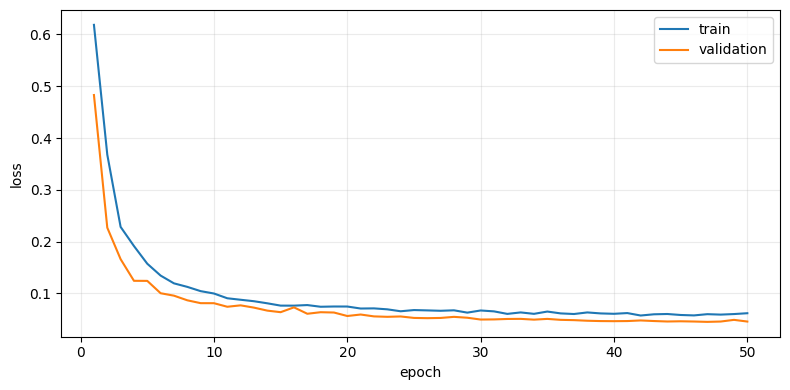

曲线已保存到 Drive
完整/步级训练状态: checkpoints/epoch_*/state.pt
中间进度与诊断快照: intermediate_state.pt
最新模型: last_model.pt；最佳模型: best_model.pt；最终模型: final_model.pt


In [18]:
import csv
import shutil
import matplotlib.pyplot as plt

run_dir = LOCAL_ROOT / RUN_ID
if not (run_dir / "metrics.csv").is_file():
    run_dir = PERSISTENT_ROOT / RUN_ID
with (run_dir / "metrics.csv").open(encoding="utf-8", newline="") as stream:
    rows = list(csv.DictReader(stream))
print("最后一行指标:", rows[-1] if rows else "暂无")
if rows:
    plt.figure(figsize=(8, 4))
    plt.plot([int(r["epoch"]) for r in rows], [float(r["train_loss"]) for r in rows], label="train")
    plt.plot([int(r["epoch"]) for r in rows], [float(r["val_loss"]) for r in rows], label="validation")
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    figure = run_dir / "loss_curve.png"
    plt.savefig(figure, dpi=150)
    plt.show()
    shutil.copyfile(figure, PERSISTENT_ROOT / RUN_ID / "loss_curve.png")
    print("曲线已保存到 Drive")
print("完整/步级训练状态: checkpoints/epoch_*/state.pt")
print("中间进度与诊断快照: intermediate_state.pt")
print("最新模型: last_model.pt；最佳模型: best_model.pt；最终模型: final_model.pt")

## 9. 断线后的进程检查（需要时运行）

先连接原服务器，检查是否仍有训练进程。看到旧训练仍在运行时不要再启动。
同一个运行时、同一个本地实验目录的重复训练会被文件锁阻止；不同服务器间仍需要你避免重复运行。

若运行时已消失，原进程和临时盘都不可依赖；重做 1～4（第 3 步会自动从 Drive 恢复代码）后执行第 7 步。

In [19]:
result = subprocess.run(["ps", "-eo", "pid,etime,args"], capture_output=True, text=True, check=True)
matching = [line for line in result.stdout.splitlines() if "colab_training_demo.train" in line]
print("\n".join(matching) if matching else "当前服务器未发现示例训练进程")
print("核对 RUN_ID、检查点轮数和更新时间后，再决定续训。")

当前服务器未发现示例训练进程
核对 RUN_ID、检查点轮数和更新时间后，再决定续训。
